# PTF10 – Introduction to Data Science · Final Project
## ClinVar: Exploring 9 Million Genetic Variant Records

**Group members:** _(add names here)_

**General objective:** using Python in a Jupyter Notebook, analyze an open-source dataset.
**Our question:** what does the world's largest public database of genetic variants tell us about how much we know, how much we trust it, and where experts disagree?

> We study patterns in a public database. We do **not** diagnose anyone or give medical advice.

# PART 1: DATASET

**1.1 Dataset Name/Title:** ClinVar Variant Summary (`variant_summary.txt.gz`)

**1.2 Data Source:** National Center for Biotechnology Information (NCBI), U.S. National Institutes of Health (NIH)

**1.3 URL:** https://ftp.ncbi.nlm.nih.gov/pub/clinvar/tab_delimited/variant_summary.txt.gz
(about page: https://www.ncbi.nlm.nih.gov/clinvar/)

**1.4 Overview:** ClinVar is a free public archive where clinical labs, researchers and expert panels report what they think a human genetic variant (a change in the DNA letters) does to health: *pathogenic* (causes disease), *benign* (harmless), or *uncertain*. Each row is one variant on one genome build, with its gene, location, the condition it is linked to, its clinical significance, how strongly it was reviewed, and how many labs submitted it. The file is updated regularly; we used the November 2026 release.

**1.5 Number of Rows:** 9,354,555 (raw file). After keeping one genome build (GRCh38) and removing duplicates: 4,641,203 unique variants.

**1.6 Number of Columns:** 43

**1.7 Column Descriptions:**

| # | Column | Description |
|---|---|---|
| 1 | AlleleID | ClinVar ID for the allele (the specific DNA change) |
| 2 | Type | Kind of variant: single nucleotide variant, deletion, duplication, etc. |
| 3 | Name | Standard (HGVS) name of the variant |
| 4 | GeneID | NCBI Gene ID |
| 5 | GeneSymbol | Short gene name(s), e.g. BRCA1; several separated by `;` |
| 6 | HGNC_ID | Official gene ID from the HUGO Gene Nomenclature Committee |
| 7 | ClinicalSignificance | Overall germline label: Pathogenic, Likely pathogenic, Uncertain significance, Likely benign, Benign, Conflicting… |
| 8 | ClinSigSimple | Simplified label: 1 = at least one pathogenic/likely pathogenic, 0 = none, -1 = no data |
| 9 | LastEvaluated | Date the variant was last evaluated (text, e.g. "Mar 05, 2019") |
| 10 | RS# (dbSNP) | ID in the dbSNP database |
| 11 | nsv/esv (dbVar) | ID in the dbVar database (large structural variants) |
| 12 | RCVaccession | ClinVar record IDs for each variant–condition pair |
| 13 | PhenotypeIDS | IDs of the linked conditions in other databases (MedGen, OMIM…) |
| 14 | PhenotypeList | Names of the linked conditions; several separated by `\|` |
| 15 | Origin | Where the variant came from: germline, somatic, de novo, etc. |
| 16 | OriginSimple | Simplified origin |
| 17 | Assembly | Genome build (DNA map): GRCh37, GRCh38, NCBI36 |
| 18 | ChromosomeAccession | Reference sequence ID of the chromosome |
| 19 | Chromosome | Chromosome number (1–22, X, Y, MT) |
| 20 | Start | Start position on the chromosome |
| 21 | Stop | End position on the chromosome |
| 22 | ReferenceAllele | Original DNA letters |
| 23 | AlternateAllele | Changed DNA letters |
| 24 | Cytogenetic | Chromosome band, e.g. 17q21.31 |
| 25 | ReviewStatus | How the label was reviewed (single submitter, multiple submitters, expert panel, practice guideline…) |
| 26 | NumberSubmitters | How many labs/groups submitted this variant |
| 27 | Guidelines | Guideline flags (e.g. ACMG secondary-findings list) |
| 28 | TestedInGTR | Whether a genetic test for it is listed in the Genetic Testing Registry (Y/N) |
| 29 | OtherIDs | IDs in other databases |
| 30 | SubmitterCategories | Code for the kind of organizations that submitted |
| 31 | VariationID | ClinVar variation ID (one per variant; used to remove duplicates) |
| 32 | PositionVCF | Position in VCF file format |
| 33 | ReferenceAlleleVCF | Original letters, VCF format |
| 34 | AlternateAlleleVCF | Changed letters, VCF format |
| 35 | SomaticClinicalImpact | Tumor (somatic) classification tier |
| 36 | SomaticClinicalImpactLastEvaluated | Date of that somatic classification |
| 37 | ReviewStatusClinicalImpact | Review status of the somatic classification |
| 38 | Oncogenicity | Whether the variant drives cancer (oncogenic / benign…) |
| 39 | OncogenicityLastEvaluated | Date of that oncogenicity classification |
| 40 | ReviewStatusOncogenicity | Review status of the oncogenicity classification |
| 41 | SCVsForAggregateGermlineClassification | Submission IDs behind the germline label |
| 42 | SCVsForAggregateSomaticClinicalImpact | Submission IDs behind the somatic label |
| 43 | SCVsForAggregateOncogenicityClassification | Submission IDs behind the oncogenicity label |

*Columns 1–34 are classic ClinVar fields; 35–43 were added for cancer (somatic) classifications.*

# PART 2: THE PYTHON NOTEBOOK

## 2.1 Libraries used

| Library | Used for |
|---|---|
| **pandas** | Loading the file, cleaning, grouping, counting |
| **numpy** | Missing values (`np.nan`), math (log scale) |
| **matplotlib** | All charts (titles, axes, legends, colors, fonts) |
| **seaborn** | Chart theme and the box plot |
| **os / gc** | File paths, freeing memory |

In [1]:
import os, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# One look for every chart: custom font, sizes and colors
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11, "figure.dpi": 110,
    "axes.titlesize": 15, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 12, "axes.labelweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
})
COLORS = {"P/LP": "#E4572E", "VUS": "#F3A712", "B/LB": "#3BB273",
          "Conflicting": "#5B6C8F", "Other": "#B8C4D0"}
ORDER = ["P/LP", "VUS", "B/LB", "Conflicting", "Other"]
NAMES = {"P/LP": "Pathogenic / Likely pathogenic", "VUS": "Uncertain significance (VUS)",
         "B/LB": "Benign / Likely benign", "Conflicting": "Conflicting", "Other": "Other"}
TEAL, INK = "#0FA3B1", "#14213D"
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.2.3 | numpy 2.1.3


## 2.2 Data Acquisition (How the dataset was loaded)

1. **Download** the compressed file (~440 MB) straight from NCBI with `wget`.
2. **Peek** at 5 rows to see all 43 columns.
3. **Load** with `pd.read_csv`. The full file is too big for memory, so we read it **500,000 rows at a time**, keep only the **12 columns** we need, and keep only rows on the newer genome build **GRCh38**. (Every variant is listed once per build, so this also removes the copy.)

In [2]:
USE_DRIVE = False   # True = save the download in Google Drive for next time
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = "/content/drive/MyDrive/clinvar"
else:
    DATA_DIR = "/content/clinvar"
os.makedirs(DATA_DIR, exist_ok=True)
RAW_FILE = f"{DATA_DIR}/variant_summary.txt.gz"

URL = "https://ftp.ncbi.nlm.nih.gov/pub/clinvar/tab_delimited/variant_summary.txt.gz"
if not os.path.exists(RAW_FILE):
    !wget -q --show-progress -O "{RAW_FILE}" "{URL}"
!ls -lh "{RAW_FILE}"

-rw-r--r-- 1 root root 438M Nov  9 23:26 /content/clinvar/variant_summary.txt.gz


In [3]:
peek = pd.read_csv(RAW_FILE, sep="\t", nrows=5, dtype=str)
print("Number of columns:", peek.shape[1])
peek.head()

Number of columns: 43


,#AlleleID,Type,Name,GeneID,GeneSymbol,HGNC_ID,ClinicalSignificance,ClinSigSimple,LastEvaluated,RS# (dbSNP),...,AlternateAlleleVCF,SomaticClinicalImpact,SomaticClinicalImpactLastEvaluated,ReviewStatusClinicalImpact,Oncogenicity,OncogenicityLastEvaluated,ReviewStatusOncogenicity,SCVsForAggregateGermlineClassification,SCVsForAggregateSomaticClinicalImpact,SCVsForAggregateOncogenicityClassification
0,15041,Indel,NM_014855.3(AP5Z1):c.80_83delinsTGCTGTAAACTGTA...,9907,AP5Z1,HGNC:22197,Pathogenic/Likely pathogenic,1,"Dec 17, 2024",397704705,...,TGCTGTAAACTGTAACTGTAAA,-,-,-,-,-,-,SCV001451119|SCV005622007|SCV005909190,-,-
1,15041,Indel,NM_014855.3(AP5Z1):c.80_83delinsTGCTGTAAACTGTA...,9907,AP5Z1,HGNC:22197,Pathogenic/Likely pathogenic,1,"Dec 17, 2024",397704705,...,TGCTGTAAACTGTAACTGTAAA,-,-,-,-,-,-,SCV001451119|SCV005622007|SCV005909190,-,-
2,15042,Deletion,NM_014855.3(AP5Z1):c.1413_1426del (p.Leu473fs),9907,AP5Z1,HGNC:22197,Pathogenic,1,"Jun 29, 2010",397704709,...,G,-,-,-,-,-,-,SCV000020156,-,-
3,15042,Deletion,NM_014855.3(AP5Z1):c.1413_1426del (p.Leu473fs),9907,AP5Z1,HGNC:22197,Pathogenic,1,"Jun 29, 2010",397704709,...,G,-,-,-,-,-,-,SCV000020156,-,-
4,15043,single nucleotide variant,NM_014630.3(ZNF592):c.3136G>A (p.Gly1046Arg),9640,ZNF592,HGNC:28986,Uncertain significance,0,"Jun 29, 2015",150829393,...,A,-,-,-,-,-,-,SCV000020157,-,-


In [4]:
COLS = ["VariationID", "Type", "GeneSymbol", "ClinicalSignificance", "ReviewStatus",
        "NumberSubmitters", "PhenotypeList", "Assembly", "Chromosome", "Start", "Stop",
        "LastEvaluated"]
missing_cols = [c for c in COLS if c not in peek.columns]
assert not missing_cols, f"ClinVar renamed these columns: {missing_cols}"

total_rows, parts = 0, []
for chunk in pd.read_csv(RAW_FILE, sep="\t", usecols=COLS, dtype=str,
                         chunksize=500_000, quoting=3):   # quoting=3: quote marks are plain text
    total_rows += len(chunk)
    parts.append(chunk[chunk["Assembly"] == "GRCh38"].drop(columns="Assembly"))
df = pd.concat(parts, ignore_index=True)
del parts; gc.collect()

print(f"Rows in the raw file:     {total_rows:,}")
print(f"Rows kept (GRCh38 build): {len(df):,}")
print("Shape:", df.shape)
dtypes_before = df.dtypes.value_counts()   # everything is text (object) at this point

Rows in the raw file:     9,354,555
Rows kept (GRCh38 build): 4,643,623
Shape: (4643623, 11)


## 2.3 Data Cleaning and Exploration
### 2.3.1 Data Cleaning

First, **duplicates**: a variant should appear once. We keep one row per `VariationID`.

In [5]:
before = len(df)
df = df.drop_duplicates(subset="VariationID").reset_index(drop=True)
print(f"Duplicates removed: {before - len(df):,}  ->  {len(df):,} unique variants")

Duplicates removed: 2,420  ->  4,641,203 unique variants


#### 2.3.1.1 Handling Missing Values

ClinVar never leaves a cell empty. It writes *missing* in many ways: `-`, `na`, `not provided`, `not specified`, `See cases`, `-1`. Pandas would count these as real values, so we:
1. **measure** how often each code appears,
2. **replace** all of them with a real missing value (`NaN`),
3. **decide per column** what to do (see table after the code).

Real NaN before: 0 | hidden missing codes: 2864360


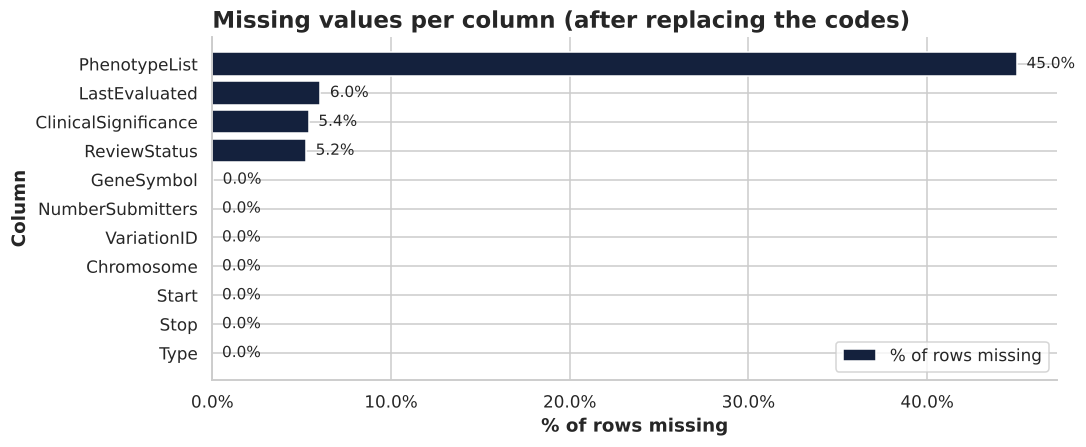

In [6]:
MISSING = ["-", "na", "NA", "", "not provided", "not specified", "See cases", "-1"]
hidden_missing = pd.Series({c: df[c].isin(MISSING).sum() for c in df.columns})
print("Real NaN before:", int(df.isna().sum().sum()), "| hidden missing codes:", int(hidden_missing.sum()))

for c in df.columns:                       # column by column to save memory
    df[c] = df[c].replace(MISSING, np.nan)

missing_pct = (df.isna().mean() * 100).sort_values()
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.barh(missing_pct.index, missing_pct.values, color=INK, label="% of rows missing")
for i, v in enumerate(missing_pct.values):
    ax.text(v, i, f"  {v:.1f}%", va="center", fontsize=10)
ax.set_title("Missing values per column (after replacing the codes)")
ax.set_xlabel("% of rows missing"); ax.set_ylabel("Column")
ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

**What we did with each missing value:**

| Column | Missing | Decision | Why |
|---|---|---|---|
| PhenotypeList (condition) | ~45% | Keep as NaN; skip in condition chart | Labs often don't name a condition; dropping would lose almost half the data |
| LastEvaluated (date) | ~6% | Keep as NaN; skip in yearly chart | Only that chart needs a date |
| ClinicalSignificance / ReviewStatus | ~5% | Keep; label as "no germline label" and leave out of label charts | These are mostly tumor (somatic) records that use a different system |
| GeneSymbol | <0.1% | Keep; skip in gene charts | Too few to matter |

We **do not drop whole rows**, because a row missing one field still has useful information in the others.

#### 2.3.1.2 Removing Outliers

We check the three numeric columns:

1. **LastEvaluated (dates):** dates before 1990 are impossible placeholders (ClinVar started in 2013; the oldest value is 1965-01-01). We set them to missing.
2. **NumberSubmitters:** the IQR rule flags anything above 1, about 22% of rows. These are **real** (popular variants get many labs), so we keep them. Not every "statistical outlier" is an error.
3. **Variant length** (`Stop - Start + 1`): most variants are 1 letter long, but a few huge copy-number changes span millions of letters (max ~159 million). They are real, but they squash every chart, so we **remove the top 0.1%** from the length analysis only.

Dates before 1990 set to missing: 111  (oldest was 1965-01-01)


Submitters IQR fence = 1.0: would flag 22.5% of rows -> kept (real data)


Length cut-off (99.9th percentile): 1,414,442 letters; removed 4,642 extreme rows from the length analysis


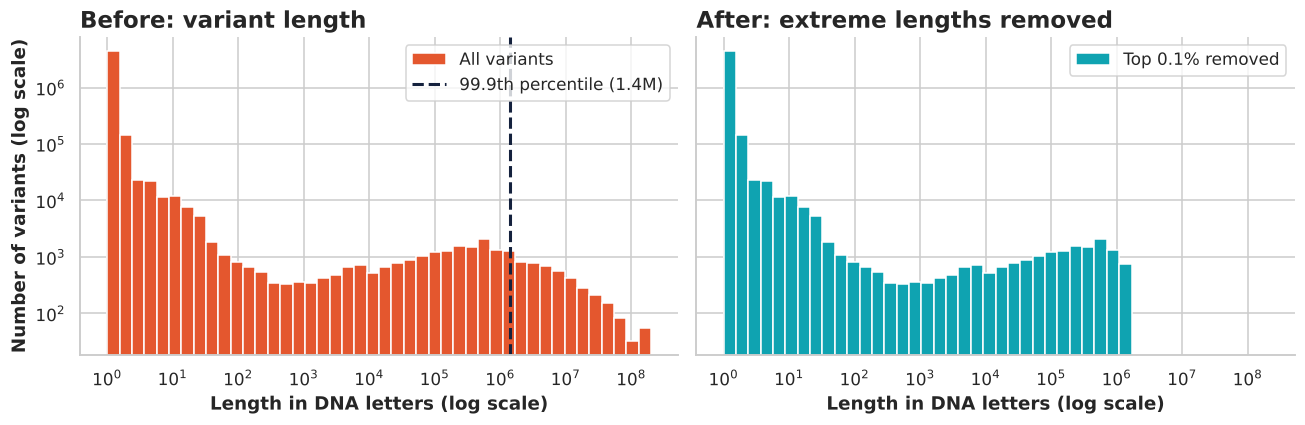

In [7]:
# 1. Dates
df["LastEvaluated"] = pd.to_datetime(df["LastEvaluated"], format="%b %d, %Y", errors="coerce")
bad_dates = df["LastEvaluated"] < "1990-01-01"
print(f"Dates before 1990 set to missing: {bad_dates.sum():,}  (oldest was {df['LastEvaluated'].min().date()})")
df.loc[bad_dates, "LastEvaluated"] = pd.NaT

# 2. Number of submitters: IQR check
df["NumberSubmitters"] = pd.to_numeric(df["NumberSubmitters"], errors="coerce")
q1, q3 = df["NumberSubmitters"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print(f"Submitters IQR fence = {upper}: would flag {(df['NumberSubmitters'] > upper).mean()*100:.1f}% of rows -> kept (real data)")

# 3. Variant length
for c in ["Start", "Stop"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df["Length"] = df["Stop"] - df["Start"] + 1
cut = df["Length"].quantile(0.999)
length_clean = df.loc[df["Length"] <= cut, "Length"]
print(f"Length cut-off (99.9th percentile): {cut:,.0f} letters; removed {(df['Length'] > cut).sum():,} extreme rows from the length analysis")

bins = np.logspace(0, np.log10(df["Length"].max()) + 0.1, 45)   # equal-width bins on a log scale
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
axes[0].hist(df["Length"].dropna(), bins=bins, color="#E4572E", label="All variants")
axes[0].axvline(cut, color=INK, linestyle="--", linewidth=2, label=f"99.9th percentile ({cut/1e6:.1f}M)")
axes[0].set_title("Before: variant length")
axes[1].hist(length_clean, bins=bins, color=TEAL, label="Top 0.1% removed")
axes[1].set_title("After: extreme lengths removed")
for ax in axes:
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("Length in DNA letters (log scale)"); ax.legend()
axes[0].set_ylabel("Number of variants (log scale)")
plt.tight_layout(); plt.show()

#### 2.3.1.3 Converting data types if necessary

Everything was loaded as text (`object`). We convert:
- `Start`, `Stop`, `NumberSubmitters` → **numbers** (done in 2.3.1.2, needed for the outlier checks)
- `LastEvaluated` → **datetime** (done in 2.3.1.2), plus a `Year` column
- repeated text (`Type`, `Chromosome`, labels) → **category** (saves memory)

We also create two **new columns** from messy text:
- `Group`: 100+ label spellings → 5 groups (P/LP, VUS, B/LB, Conflicting, Other)
- `Stars`: review status text → a 0–4 trust score (ClinVar's star system)

In [8]:
print("Data types when loaded:"); print(dtypes_before.to_string(), "\n")

def sig_group(label):
    s = label.lower()
    if "conflicting" in s: return "Conflicting"
    path, ben = "pathogenic" in s, "benign" in s
    if path and not ben: return "P/LP"
    if ben and not path: return "B/LB"
    if "uncertain" in s or s.startswith("vus"): return "VUS"
    return "Other"

def stars(status):
    s = status.lower()
    if "practice guideline" in s: return 4
    if "expert panel" in s: return 3
    if "multiple submitters" in s and "no conflict" in s: return 2
    if "criteria provided" in s: return 1
    return 0

labels = df["ClinicalSignificance"].dropna().unique()
print(f"Different spellings of the label: {len(labels)}")
df["Group"] = df["ClinicalSignificance"].map({l: sig_group(l) for l in labels})
df["Stars"] = df["ReviewStatus"].map({s: stars(s) for s in df["ReviewStatus"].dropna().unique()}).fillna(0).astype("int8")
df["Year"] = df["LastEvaluated"].dt.year.astype("Int64")

for c in ["Type", "Chromosome", "ClinicalSignificance", "ReviewStatus", "Group"]:
    df[c] = df[c].astype("category")
gc.collect()
print("\nData types AFTER:"); print(df.dtypes.to_string())

Data types when loaded:
object    11 



Different spellings of the label: 104



Data types AFTER:
Type                          category
GeneSymbol                      object
ClinicalSignificance          category
LastEvaluated           datetime64[ns]
PhenotypeList                   object
Chromosome                    category
Start                            int64
Stop                             int64
ReviewStatus                  category
NumberSubmitters                 int64
VariationID                     object
Length                           int64
Group                         category
Stars                             int8
Year                             Int64


### 2.3.2 Data Exploration

In [9]:
df.head()

,Type,GeneSymbol,ClinicalSignificance,LastEvaluated,PhenotypeList,Chromosome,Start,Stop,ReviewStatus,NumberSubmitters,VariationID,Length,Group,Stars,Year
0,Indel,AP5Z1,Pathogenic/Likely pathogenic,2024-12-17,Hereditary spastic paraplegia 48|Macular dystr...,7,4781213,4781216,"criteria provided, multiple submitters, no con...",4,2,4,P/LP,2,2024
1,Deletion,AP5Z1,Pathogenic,2010-06-29,Hereditary spastic paraplegia 48,7,4787730,4787743,no assertion criteria provided,1,3,14,P/LP,1,2010
2,single nucleotide variant,ZNF592,Uncertain significance,2015-06-29,Galloway-Mowat syndrome 1,15,84799209,84799209,no assertion criteria provided,1,4,1,VUS,1,2015
3,single nucleotide variant,FOXRED1,Pathogenic,2025-08-17,"Mitochondrial complex I deficiency, nuclear ty...",11,126275389,126275389,"criteria provided, multiple submitters, no con...",6,5,1,P/LP,2,2025
4,single nucleotide variant,FOXRED1,Likely pathogenic,2024-06-06,"Mitochondrial complex I deficiency, nuclear ty...",11,126277517,126277517,"criteria provided, single submitter",2,6,1,P/LP,1,2024


In [10]:
df.tail()

,Type,GeneSymbol,ClinicalSignificance,LastEvaluated,PhenotypeList,Chromosome,Start,Stop,ReviewStatus,NumberSubmitters,VariationID,Length,Group,Stars,Year
4641198,single nucleotide variant,DICER1,Likely benign,2026-08-17,DICER1-related tumor predisposition,14,95106238,95106238,"criteria provided, single submitter",1,5042479,1,B/LB,1,2026
4641199,single nucleotide variant,NF1,Benign,2026-09-23,"Neurofibromatosis, type 1",17,31374165,31374165,"criteria provided, single submitter",1,5042480,1,B/LB,1,2026
4641200,single nucleotide variant,NF1,Likely benign,2026-09-22,"Neurofibromatosis, type 1",17,31259017,31259017,"criteria provided, single submitter",1,5042481,1,B/LB,1,2026
4641201,single nucleotide variant,BTK,Likely pathogenic,2026-09-30,X-linked agammaglobulinemia,X,101358490,101358490,no assertion criteria provided,1,5042482,1,P/LP,1,2026
4641202,single nucleotide variant,KIF11,Pathogenic,2026-10-25,Microcephaly with or without chorioretinopathy...,10,92637310,92637310,"criteria provided, single submitter",1,5042483,1,P/LP,1,2026


In [11]:
df.info(memory_usage='deep')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4641203 entries, 0 to 4641202
Data columns (total 15 columns):
 #   Column                Dtype         
---  ------                -----         
 0   Type                  category      
 1   GeneSymbol            object        
 2   ClinicalSignificance  category      
 3   LastEvaluated         datetime64[ns]
 4   PhenotypeList         object        
 5   Chromosome            category      
 6   Start                 int64         
 7   Stop                  int64         
 8   ReviewStatus          category      
 9   NumberSubmitters      int64         
 10  VariationID           object        
 11  Length                int64         
 12  Group                 category      
 13  Stars                 int8          
 14  Year                  Int64         
dtypes: Int64(1), category(5), datetime64[ns](1), int64(4), int8(1), object(3)
memory usage: 1.0 GB


In [12]:
# Numeric columns
df[["NumberSubmitters", "Length", "Stars", "Year"]].describe().round(2)

,NumberSubmitters,Length,Stars,Year
count,4641203.00,4.641203e+06,4641203.00,4361004.0
mean,1.51,1.236955e+04,1.12,2023.32
std,1.56,7.531565e+05,0.47,2.45
min,0.00,1.000000e+00,0.00,1990.0
25%,1.00,1.000000e+00,1.00,2022.0
50%,1.00,1.000000e+00,1.00,2024.0
75%,1.00,1.000000e+00,1.00,2025.0
max,97.00,1.592282e+08,4.00,2026.0


In [13]:
# Text / category columns: how many unique values, most common value
df[["Type", "GeneSymbol", "Group", "ReviewStatus", "Chromosome"]].describe()

,Type,GeneSymbol,Group,ReviewStatus,Chromosome
count,4641203,4639552,4391047,4398105,4641203
unique,12,30373,5,9,26
top,single nucleotide variant,TTN,VUS,"criteria provided, single submitter",1
freq,4289723,41007,2398705,3304346,418240


In [14]:
labeled = df[df["Group"].notna()]       # variants with a germline label
print(f"Variants with a germline label: {len(labeled):,}\n")
print("Share of each label group (%):")
print((labeled["Group"].value_counts(normalize=True) * 100).round(2).to_string())
print("\nUnique genes:", df["GeneSymbol"].nunique())
print("Median submitters per variant:", df["NumberSubmitters"].median())

Variants with a germline label: 4,391,047

Share of each label group (%):
Group
VUS            54.63
B/LB           32.47
P/LP            8.58
Conflicting     4.20
Other           0.12

Unique genes: 30373
Median submitters per variant: 1.0


## 2.4 Exploratory Data Analysis (EDA)
### 2.4.1 Visualize Data

Eight charts: **pie, bar, line, histogram, scatter, stacked bar**. Every chart has a title, x/y axis labels and a legend. Colors mean the same thing everywhere: red = pathogenic, amber = uncertain, green = benign, slate = conflicting.

#### Chart 1 · Pie chart: how much do we know?

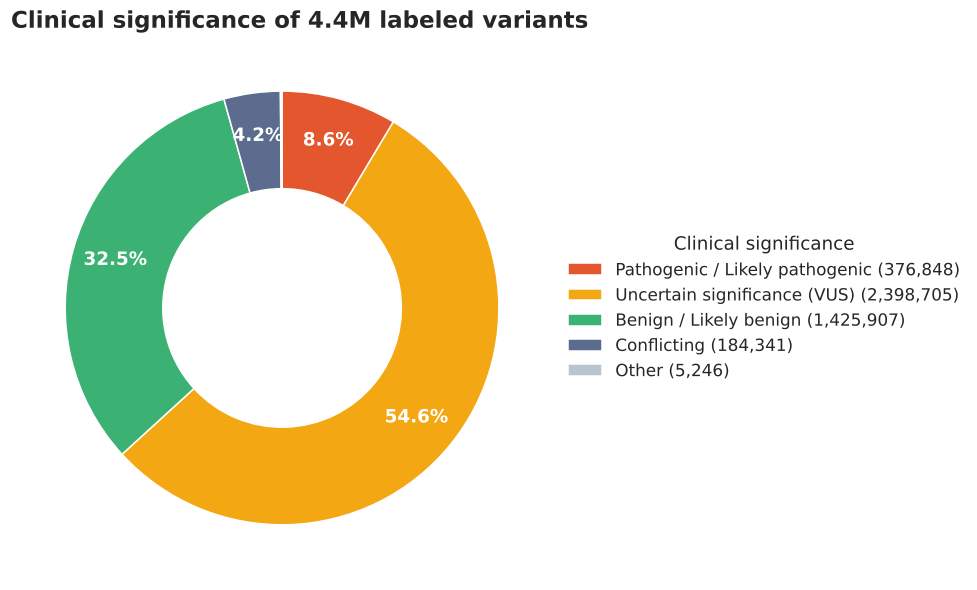

In [15]:
share = labeled["Group"].value_counts().reindex(ORDER)
fig, ax = plt.subplots(figsize=(10, 5.5))
wedges, _, autotexts = ax.pie(share, colors=[COLORS[g] for g in ORDER], startangle=90, counterclock=False,
                              autopct=lambda p: f"{p:.1f}%" if p > 3 else "", pctdistance=0.8,
                              wedgeprops=dict(width=0.45, edgecolor="white"))
plt.setp(autotexts, color="white", fontweight="bold", fontsize=12)
ax.legend(wedges, [f"{NAMES[g]} ({share[g]:,})" for g in ORDER], title="Clinical significance",
          loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
ax.set_title("Clinical significance of 4.4M labeled variants")
plt.tight_layout(); plt.show()

#### Chart 2 · Bar chart: genes with the most pathogenic variants

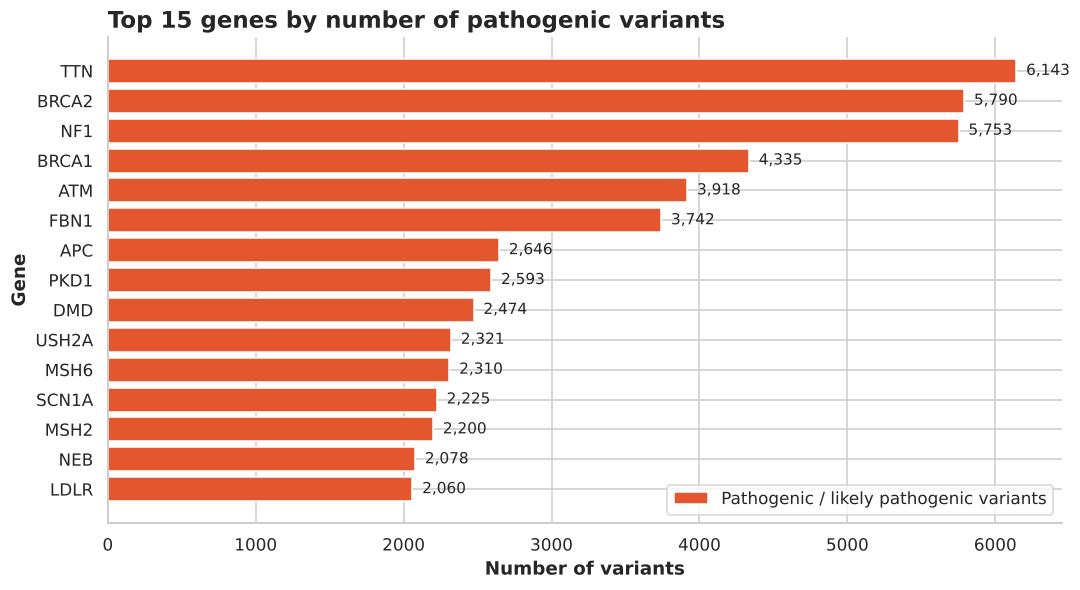

In [16]:
plp_genes = (labeled.loc[labeled["Group"] == "P/LP", "GeneSymbol"].dropna()
             .str.split(";").explode().value_counts().head(15).sort_values())
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(plp_genes.index, plp_genes.values, color=COLORS["P/LP"], label="Pathogenic / likely pathogenic variants")
for i, v in enumerate(plp_genes.values):
    ax.text(v, i, f"  {v:,}", va="center", fontsize=10)
ax.set_title("Top 15 genes by number of pathogenic variants")
ax.set_xlabel("Number of variants"); ax.set_ylabel("Gene"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

#### Chart 3 · Line plot: reviews per year

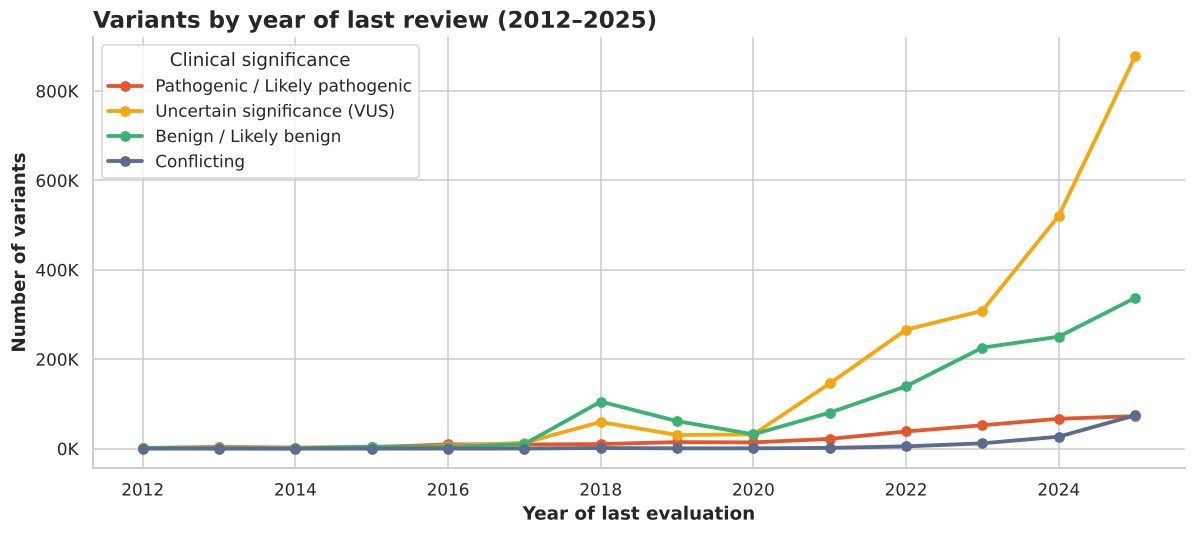

In [17]:
yearly = (labeled[labeled["Year"].between(2012, 2025)]
          .groupby(["Year", "Group"], observed=True).size()
          .unstack(fill_value=0).reindex(columns=ORDER, fill_value=0))
fig, ax = plt.subplots(figsize=(11, 5))
for g in ORDER[:4]:
    ax.plot(yearly.index, yearly[g], marker="o", linewidth=2.5, color=COLORS[g], label=NAMES[g])
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e3:,.0f}K"))
ax.set_title("Variants by year of last review (2012–2025)")
ax.set_xlabel("Year of last evaluation"); ax.set_ylabel("Number of variants")
ax.legend(title="Clinical significance"); plt.tight_layout(); plt.show()

#### Chart 4 · Histogram: how many labs report each variant?

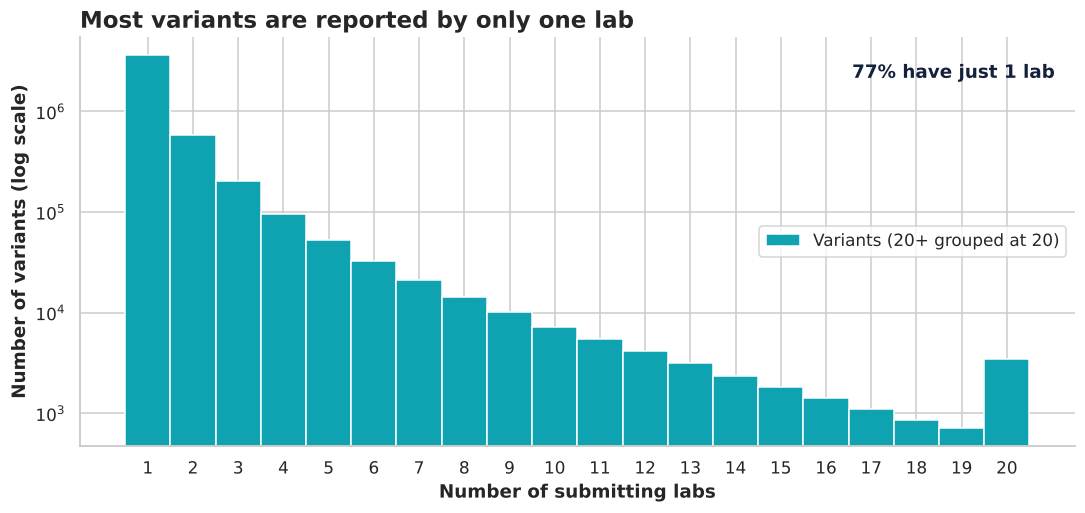

In [18]:
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.hist(df["NumberSubmitters"].clip(upper=20), bins=np.arange(0.5, 21.5, 1),
        color=TEAL, edgecolor="white", label="Variants (20+ grouped at 20)")
ax.set_yscale("log")
ax.set_title("Most variants are reported by only one lab")
ax.set_xlabel("Number of submitting labs"); ax.set_ylabel("Number of variants (log scale)")
ax.set_xticks(range(1, 21)); ax.legend()
one = (df["NumberSubmitters"] == 1).mean() * 100
ax.text(0.98, 0.9, f"{one:.0f}% have just 1 lab", transform=ax.transAxes, ha="right", fontsize=12, fontweight="bold", color=INK)
plt.tight_layout(); plt.show()

#### Chart 5 · Scatter plot: do bigger genes have more disagreement?

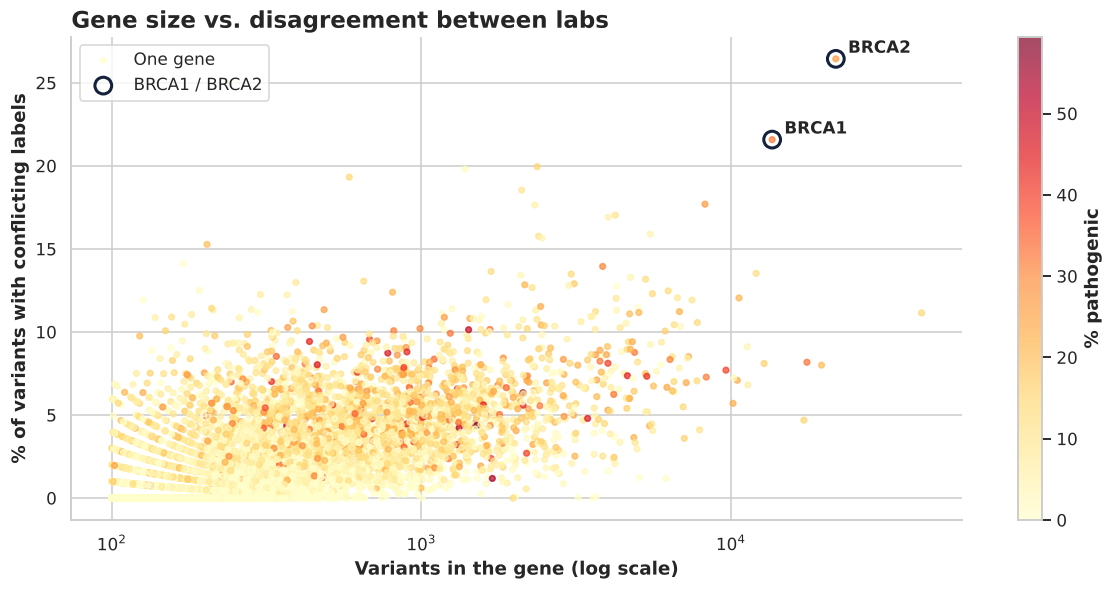

Genes plotted: 7,288 | Spearman correlation (size vs conflict): 0.68


In [19]:
g = labeled[["GeneSymbol", "Group"]].dropna()
g = g.assign(GeneSymbol=g["GeneSymbol"].str.split(";")).explode("GeneSymbol")
gt = g.groupby("GeneSymbol")["Group"].value_counts().unstack(fill_value=0)
gt["n"] = gt.sum(axis=1)
gt = gt[gt["n"] >= 100]
gt["conflict_pct"] = gt["Conflicting"] / gt["n"] * 100
gt["plp_pct"] = gt["P/LP"] / gt["n"] * 100

fig, ax = plt.subplots(figsize=(11, 5.5))
sc = ax.scatter(gt["n"], gt["conflict_pct"], c=gt["plp_pct"], cmap="YlOrRd", s=14, alpha=0.7, label="One gene")
brca = gt.loc[gt.index.isin(["BRCA1", "BRCA2"])]
ax.scatter(brca["n"], brca["conflict_pct"], s=120, facecolors="none", edgecolors=INK, linewidths=2, label="BRCA1 / BRCA2")
for name, row in brca.iterrows():
    ax.annotate(name, (row["n"], row["conflict_pct"]), xytext=(8, 4), textcoords="offset points", fontweight="bold")
ax.set_xscale("log")
plt.colorbar(sc, ax=ax, label="% pathogenic")
ax.set_title("Gene size vs. disagreement between labs")
ax.set_xlabel("Variants in the gene (log scale)"); ax.set_ylabel("% of variants with conflicting labels")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

corr = gt["n"].rank().corr(gt["conflict_pct"].rank())   # Spearman = correlation of ranks
print(f"Genes plotted: {len(gt):,} | Spearman correlation (size vs conflict): {corr:.2f}")

#### Chart 6 · Stacked bar chart: does the type of DNA change matter?

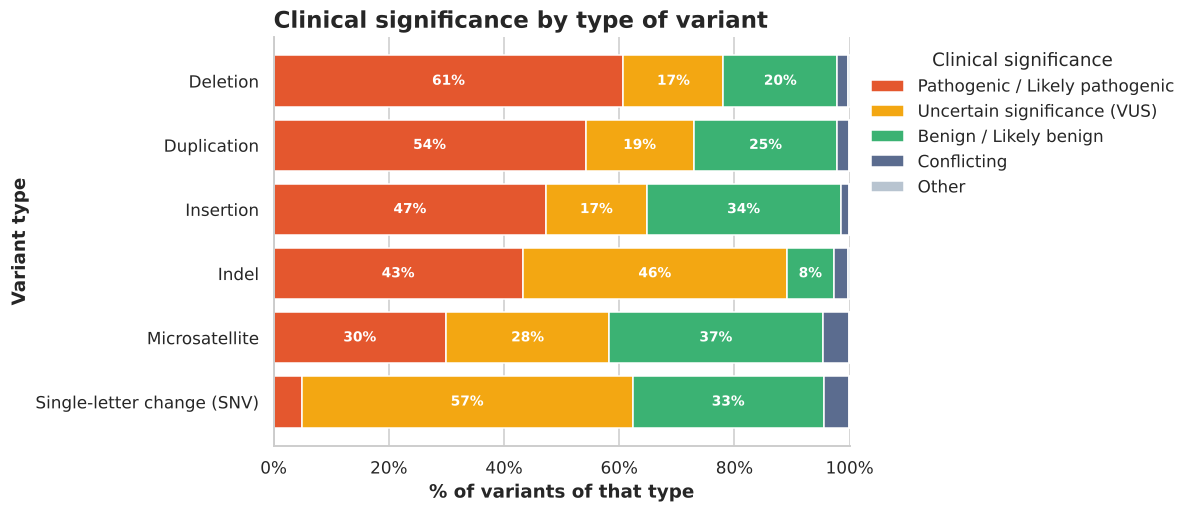

In [20]:
top_types = labeled["Type"].value_counts().head(6).index
sub = labeled[labeled["Type"].isin(top_types)]
ct = (pd.crosstab(sub["Type"].astype(str), sub["Group"], normalize="index") * 100).reindex(columns=ORDER).fillna(0)
ct = ct.rename(index={"single nucleotide variant": "Single-letter change (SNV)"}).sort_values("P/LP")
fig, ax = plt.subplots(figsize=(11, 4.8))
left = np.zeros(len(ct))
for grp in ORDER:
    ax.barh(ct.index, ct[grp], left=left, color=COLORS[grp], label=NAMES[grp])
    for i, (l, v) in enumerate(zip(left, ct[grp])):
        if v > 7: ax.text(l + v / 2, i, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    left += ct[grp].values
ax.set_title("Clinical significance by type of variant")
ax.set_xlabel("% of variants of that type"); ax.set_ylabel("Variant type")
ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_xlim(0, 100)
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False, title="Clinical significance")
plt.tight_layout(); plt.show()

#### Chart 7 · Bar chart: how trustworthy are the labels?

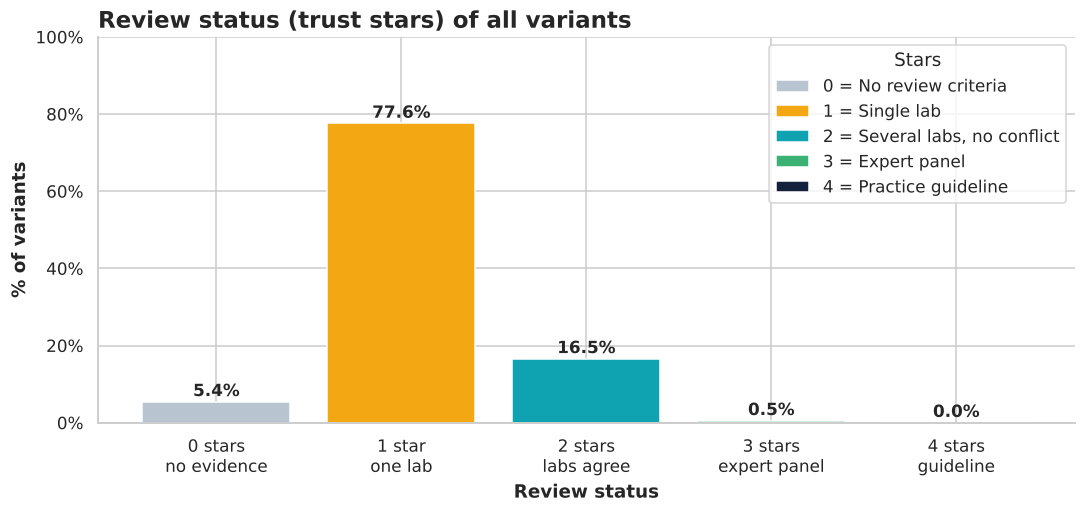

In [21]:
sc_ = df["Stars"].value_counts().reindex(range(5), fill_value=0)
pct = sc_ / sc_.sum() * 100
names = ["0 stars\nno evidence", "1 star\none lab", "2 stars\nlabs agree", "3 stars\nexpert panel", "4 stars\nguideline"]
fig, ax = plt.subplots(figsize=(10, 4.8))
star_colors = ["#B8C4D0", "#F3A712", TEAL, "#3BB273", INK]
meaning = ["No review criteria", "Single lab", "Several labs, no conflict", "Expert panel", "Practice guideline"]
for i in range(5):
    ax.bar(names[i], pct[i], color=star_colors[i], label=f"{i} = {meaning[i]}")
    ax.text(i, pct[i] + 1.5, f"{pct[i]:.1f}%", ha="center", fontweight="bold")
ax.set_title("Review status (trust stars) of all variants")
ax.set_xlabel("Review status"); ax.set_ylabel("% of variants")
ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_ylim(0, 100); ax.legend(title="Stars")
plt.tight_layout(); plt.show()

#### Chart 8 · Bar chart: conditions linked to pathogenic variants

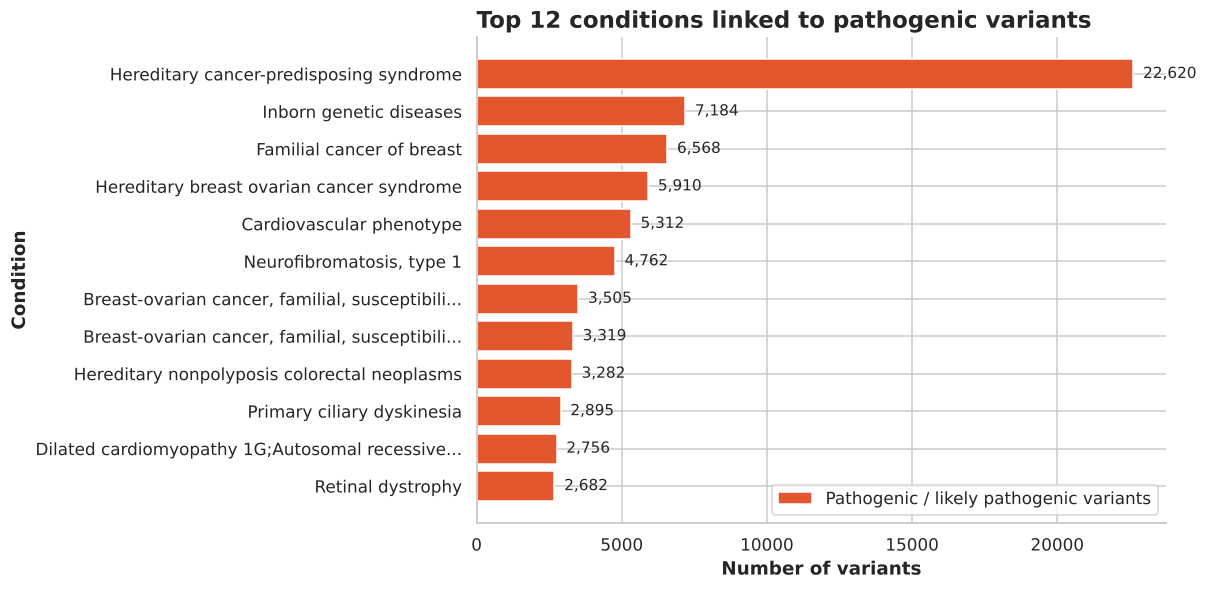

In [22]:
ph = labeled.loc[labeled["Group"] == "P/LP", "PhenotypeList"].dropna().str.split("|").explode().str.strip()
ph = ph[~ph.str.lower().isin(["not provided", "not specified", "see cases"])]
top = ph.value_counts().head(12).sort_values()
names = [t if len(t) <= 48 else t[:45] + "..." for t in top.index]
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.barh(range(len(top)), top.values, color=COLORS["P/LP"], label="Pathogenic / likely pathogenic variants")
ax.set_yticks(range(len(top)), names)
for i, v in enumerate(top.values):
    ax.text(v, i, f"  {v:,}", va="center", fontsize=10)
ax.set_title("Top 12 conditions linked to pathogenic variants")
ax.set_xlabel("Number of variants"); ax.set_ylabel("Condition"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

### 2.4.2 Insights

1. **We still don't know most of it (Chart 1).** 54.6% of labeled variants are *uncertain* (VUS). Only 8.6% are pathogenic and 32.5% benign. When a patient's DNA test finds a VUS, doctors can't say if it's dangerous.
2. **The same genes keep coming up (Chart 2).** TTN, BRCA2, NF1, BRCA1 and ATM have the most pathogenic variants. TTN is the largest human gene; BRCA1/2 are the main breast/ovarian cancer genes.
3. **Uncertainty is growing faster than answers (Chart 3).** Reviews jumped from about 33K variants (2017) to about 1.36M (2025). The *uncertain* line rises far faster than the *pathogenic* line.
4. **Most variants have no second opinion (Chart 4).** About 77% are reported by just one lab, even though a few popular variants have up to 97.
5. **Bigger, well-studied genes have more disagreement (Chart 5).** The more variants a gene has, the higher its share of conflicting labels tends to be. Across 7,288 genes the rank correlation is 0.68 (strong). BRCA2 (26%) and BRCA1 (22%) stand out: more labs testing means more chances to disagree.
6. **Big DNA changes are easier to judge (Chart 6).** Deletions (61%) and duplications (54%) are mostly pathogenic, while single-letter changes are only ~5% pathogenic and ~57% uncertain. Most of the "unknown" problem is single-letter changes.
7. **Expert review is rare (Chart 7).** 77.6% of variants carry only 1 star (one lab's opinion); just 0.5% were checked by an expert panel or practice guideline.
8. **Cancer leads the conditions (Chart 8).** "Hereditary cancer-predisposing syndrome" is linked to ~22,600 pathogenic variants, far ahead of everything else; breast/ovarian cancer appears several times.
9. **Cleaning mattered.** Without it every count would be doubled (two genome builds), 104 label spellings would split the charts, and 45% of condition values hide behind codes like "not provided".

*These are patterns in a public database, not medical advice.*

### Save the clean data (optional)

In [23]:
df.to_parquet(f"{DATA_DIR}/clinvar_grch38_clean.parquet", index=False)
print("Saved clean data:", f"{DATA_DIR}/clinvar_grch38_clean.parquet")

Saved clean data: /content/clinvar/clinvar_grch38_clean.parquet
